# Healthy Minds Study (HMS) — Full Dataset Exploration (2007–2025)

This notebook provides a structured, end-to-end exploration of all **11 CSV files** in this folder.

**What is HMS?** The [Healthy Minds Study](https://healthymindsnetwork.org/) is a national survey of college-student mental health, administered annually at participating U.S. institutions. The files here span:

| Period | File | Notes |
|--------|------|-------|
| 2007–2013 | `HMS_2007-2013_Aggregate.csv` | Pooled early years, single schema |
| 2013–2014 | `HMS_2013-2014_PUBLIC.csv` | Transition year |
| 2016–2017 | `HMS_2016-2017_PUBLIC.csv` | Expanded questionnaire |
| 2017–2025 | `HMS_*_PUBLIC_instchars.csv` | Respondent data **plus institution characteristics** |

**Topics covered in the surveys:** depression (PHQ-9), anxiety (GAD-7), eating disorders, self-injury, suicidal ideation, substance use, therapy/medication use, stigma, campus climate, demographics, and (in later waves) DEI, sexual assault, financial stress, and AI use.

> **Note:** Despite the folder name, only `.csv` files are present — no `.dta` (Stata) files were found.

## 1. Setup

In [48]:
import warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100

DATA_DIR = Path(".").resolve()
CSV_FILES = sorted(DATA_DIR.glob("HMS_*.csv"))


def read_hms_csv(path: Path, **kwargs) -> pd.DataFrame:
    """Read an HMS CSV, handling mixed encodings in open-text responses."""
    opts = {"low_memory": False, **kwargs}
    for encoding in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, encoding=encoding, **opts)
            if encoding != "utf-8":
                print(f"[{encoding}]", end=" ")
            return df
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, encoding="utf-8", encoding_errors="replace", **opts)


print(f"Data directory: {DATA_DIR}")
print(f"Found {len(CSV_FILES)} CSV files")

Data directory: C:\Users\test\Desktop\2007-2025 datasets (.csv, .dta)
Found 11 CSV files


## 2. File inventory

Quick scan of every file: rows, columns, disk size, and inferred survey year(s).

In [49]:
def infer_years(filename: str) -> str:
    """Extract year range from HMS filename."""
    name = filename.replace("HMS_", "").replace("_PUBLIC_instchars.csv", "").replace("_PUBLIC.csv", "").replace("_Aggregate.csv", "")
    return name


def count_rows_fast(path: Path) -> int:
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        return max(sum(1 for _ in f) - 1, 0)


inventory_rows = []
for path in CSV_FILES:
    header = read_hms_csv(path, nrows=0)
    inventory_rows.append({
        "file": path.name,
        "years": infer_years(path.name),
        "n_rows": count_rows_fast(path),
        "n_cols": len(header.columns),
        "size_mb": round(path.stat().st_size / 1e6, 1),
        "has_inst_chars": "instchars" in path.name.lower(),
    })

inventory = pd.DataFrame(inventory_rows)
inventory["total_cells_millions"] = (inventory["n_rows"] * inventory["n_cols"] / 1e6).round(1)
inventory

,file,years,n_rows,n_cols,size_mb,has_inst_chars,total_cells_millions
0,HMS_2007-2013_Aggregate.csv,2007-2013,89486,497,73.0,False,44.5
1,HMS_2013-2014_PUBLIC.csv,2013-2014,17584,521,19.0,False,9.2
2,HMS_2016-2017_PUBLIC.csv,2016-2017,53963,1500,213.1,False,80.9
3,HMS_2017-2018_PUBLIC_instchars.csv,2017-2018,67313,1861,343.1,True,125.3
4,HMS_2018-2019_PUBLIC_instchars.csv,2018-2019,62026,2104,371.9,True,130.5
5,HMS_2019-2020_PUBLIC_instchars.csv,2019-2020,88755,2341,290.7,True,207.8
6,HMS_2020-2021_PUBLIC_instchars.csv,2020-2021,140197,2374,821.3,True,332.8
7,HMS_2021-2022_PUBLIC_instchars.csv,2021-2022,95860,1680,229.7,True,161.0
8,HMS_2022-2023_PUBLIC_instchars.csv,2022-2023,76406,1620,361.3,True,123.8
9,HMS_2023-2024_PUBLIC_instchars.csv,2023-2024,104729,1554,202.6,True,162.7


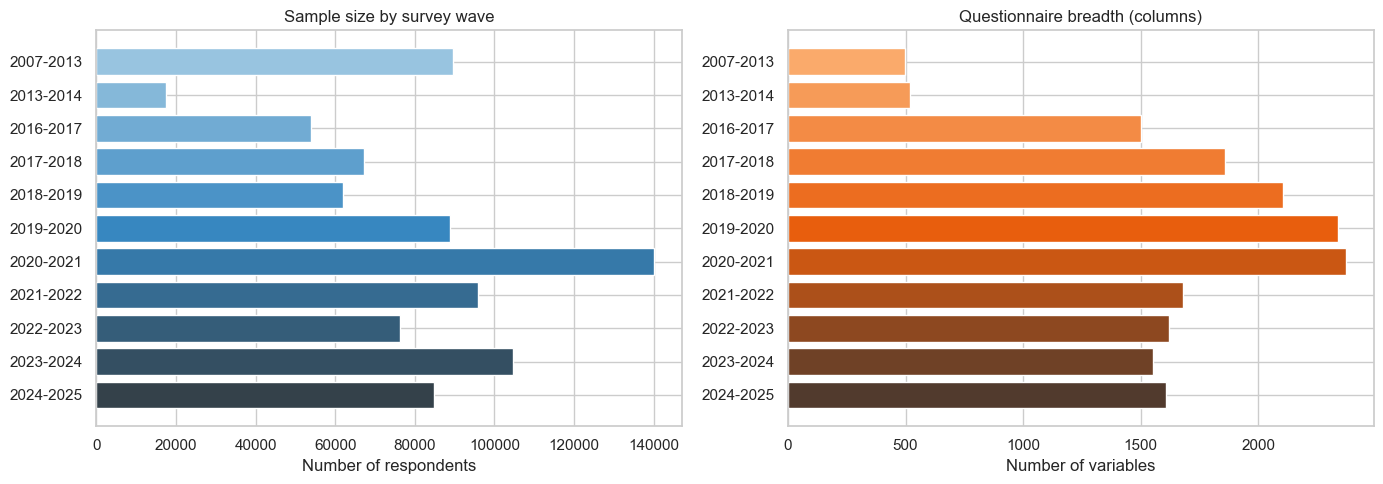

Total respondents across files: 881,054
Total disk usage: 3101 MB


In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(inventory["years"], inventory["n_rows"], color=sns.color_palette("Blues_d", len(inventory)))
axes[0].set_xlabel("Number of respondents")
axes[0].set_title("Sample size by survey wave")
axes[0].invert_yaxis()

axes[1].barh(inventory["years"], inventory["n_cols"], color=sns.color_palette("Oranges_d", len(inventory)))
axes[1].set_xlabel("Number of variables")
axes[1].set_title("Questionnaire breadth (columns)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"Total respondents across files: {inventory['n_rows'].sum():,}")
print(f"Total disk usage: {inventory['size_mb'].sum():.0f} MB")

## 3. Load all datasets

Each file is stored in a dictionary keyed by a short label. Large files may take 30–90 seconds to load depending on your machine.

In [51]:
def short_label(path: Path) -> str:
    return infer_years(path.name)


datasets = {}
for path in CSV_FILES:
    label = short_label(path)
    print(f"Loading {path.name} ...", end=" ")
    datasets[label] = read_hms_csv(path)
    print(f"{datasets[label].shape[0]:,} rows × {datasets[label].shape[1]} cols")

print(f"\nLoaded {len(datasets)} datasets.")

Loading HMS_2007-2013_Aggregate.csv ... 89,486 rows × 497 cols
Loading HMS_2013-2014_PUBLIC.csv ... 17,584 rows × 521 cols
Loading HMS_2016-2017_PUBLIC.csv ... [cp1252] 53,888 rows × 1500 cols
Loading HMS_2017-2018_PUBLIC_instchars.csv ... [cp1252] 66,814 rows × 1861 cols
Loading HMS_2018-2019_PUBLIC_instchars.csv ... 62,026 rows × 2104 cols
Loading HMS_2019-2020_PUBLIC_instchars.csv ... 88,703 rows × 2341 cols
Loading HMS_2020-2021_PUBLIC_instchars.csv ... 137,916 rows × 2374 cols
Loading HMS_2021-2022_PUBLIC_instchars.csv ... 95,860 rows × 1680 cols
Loading HMS_2022-2023_PUBLIC_instchars.csv ... 76,406 rows × 1620 cols
Loading HMS_2023-2024_PUBLIC_instchars.csv ... 104,729 rows × 1554 cols
Loading HMS_2024-2025_PUBLIC_instchars.csv ... 84,735 rows × 1608 cols

Loaded 11 datasets.


## 4. First look — structure & dtypes

In [52]:
for label, df in datasets.items():
    print("=" * 70)
    print(f"{label}  |  shape: {df.shape}")
    print(f"Columns (first 15): {list(df.columns[:15])}")
    print(f"Columns (last 5):   {list(df.columns[-5:])}")
    print(df.head(2).T.head(10))

2007-2013  |  shape: (89486, 497)
Columns (first 15): ['respid', 'survey_year', 'nrweight', 'age', 'gender', 'transgender', 'race_full', 'race_whi', 'race_bla', 'race_his', 'raceeth2', 'race_ame', 'race_ara', 'race_asi', 'race_pac']
Columns (last 5):   ['inter_n_r7', 'inter_n_r8', 'inter_n_r9', 'discrim', 'schoolnumber']
                      0           1
respid       10000_2007  10004_2007
survey_year        2007        2007
nrweight       2.674599    3.182621
age                 3.0         3.0
gender              2.0         2.0
transgender         NaN         NaN
race_full             1           1
race_whi            1.0         1.0
race_bla            0.0         0.0
race_his            0.0         0.0
2013-2014  |  shape: (17584, 521)
Columns (first 15): ['aicad', 'schoolid', 'respid', 'nrweight', 'pre_2', 'gpa', 'gpa_sr', 'survey', 'schoolnum', 'age', 'gender', 'transgender', 'race_whi', 'race_bla', 'race_his']
Columns (last 5):   ['dx_ea', 'dx_psy', 'dx_perso', 'dx_sa', 'surv

In [53]:
dtype_summary = []
for label, df in datasets.items():
    dtype_summary.append({
        "dataset": label,
        "numeric_cols": (df.dtypes != "object").sum(),
        "object_cols": (df.dtypes == "object").sum(),
        "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    })
pd.DataFrame(dtype_summary)

,dataset,numeric_cols,object_cols,memory_mb
0,2007-2013,473,24,425.9
1,2013-2014,512,9,81.4
2,2016-2017,914,586,1639.8
3,2017-2018,1803,58,1101.0
4,2018-2019,1966,138,1293.7
5,2019-2020,2200,141,2038.7
6,2020-2021,720,1654,9084.3
7,2021-2022,1547,133,1669.3
8,2022-2023,1332,288,1548.1
9,2023-2024,1455,99,1599.8


## 5. Schema comparison across waves

HMS questionnaires evolve each year. Below we identify **core variables** that appear in most files and track how column overlap changes.

In [54]:
# Core mental-health & demographic variables (may use different names across years)
CORE_CANDIDATES = {
    "survey_year": ["survey_year", "survey", "inst_HMSyear"],
    "weight": ["nrweight"],
    "age": ["age"],
    "gender": ["gender", "gender_female", "gender_male", "sex_birth"],
    "depression_score": ["deprawsc"],
    "depression_any": ["dep_any", "dep_any2"],
    "depression_major": ["dep_maj"],
    "anxiety_score": ["anx_score"],
    "anxiety_any": ["anx_any"],
    "phq9_items": [f"phq9_{i}" for i in range(1, 10)],
    "gad7_items": [f"gad7_{i}" for i in range(1, 8)],
    "therapy_any": ["ther_any", "ther_any2", "ther_lifetime"],
    "meds_any": ["meds_any"],
    "suicide_ideation": ["sui_idea", "sui_idea_ccmh_lifetime"],
    "self_injury": ["sib_any"],
    "flourishing": ["flourish", "keyes_flourish", "positiveMH", "positivemh"],
    "gpa": ["gpa", "gpa_sr"],
    "school_id": ["schoolnum", "schoolnumber", "schoolid", "school_id"],
    "inst_type": ["inst_type"],
    "inst_size": ["inst_size"],
    "inst_public": ["inst_public"],
}


def resolve_column(df: pd.DataFrame, candidates: list[str]) -> str | None:
    for c in candidates:
        if c in df.columns:
            return c
    return None


resolved = {}
for label, df in datasets.items():
    resolved[label] = {k: resolve_column(df, v) for k, v in CORE_CANDIDATES.items()}

resolved_df = pd.DataFrame(resolved).T
resolved_df

,survey_year,weight,age,gender,depression_score,depression_any,depression_major,anxiety_score,anxiety_any,phq9_items,gad7_items,therapy_any,meds_any,suicide_ideation,self_injury,flourishing,gpa,school_id,inst_type,inst_size,inst_public
2007-2013,survey_year,nrweight,age,gender,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,keyes_flourish,gpa,schoolnumber,None,None,None
2013-2014,survey_year,nrweight,age,gender,deprawsc,dep_any,dep_maj,anx_score,anx_any,None,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,gpa,schoolnum,None,None,None
2016-2017,survey,nrweight,age,gender,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,gpa_sr,schoolnum,None,None,None
2017-2018,survey,nrweight,age,gender,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,gpa_sr,None,inst_type,inst_size,inst_public
2018-2019,survey,nrweight,age,gender,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,gpa_sr,schoolnum,inst_type,inst_size,inst_public
2019-2020,survey,nrweight,age,gender,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,gpa_sr,schoolnum,inst_type,inst_size,inst_public
2020-2021,survey,nrweight,age,gender_female,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,None,schoolnum,None,None,None
2021-2022,survey,nrweight,age,gender_female,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,None,schoolnum,inst_type,inst_size,inst_public
2022-2023,None,nrweight,age,gender_female,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,None,schoolnum,inst_type,inst_size,inst_public
2023-2024,None,nrweight,age,gender_female,deprawsc,dep_any,dep_maj,anx_score,anx_any,phq9_1,gad7_1,ther_any,meds_any,sui_idea,sib_any,flourish,None,schoolnum,inst_type,inst_size,inst_public


In [55]:
# Pairwise column overlap between consecutive waves
labels = list(datasets.keys())
overlap_rows = []
for i in range(len(labels) - 1):
    a, b = labels[i], labels[i + 1]
    cols_a = set(datasets[a].columns)
    cols_b = set(datasets[b].columns)
    shared = cols_a & cols_b
    overlap_rows.append({
        "from": a,
        "to": b,
        "shared_cols": len(shared),
        "pct_of_smaller": round(100 * len(shared) / min(len(cols_a), len(cols_b)), 1),
        "only_in_from": len(cols_a - cols_b),
        "only_in_to": len(cols_b - cols_a),
    })
pd.DataFrame(overlap_rows)

,from,to,shared_cols,pct_of_smaller,only_in_from,only_in_to
0,2007-2013,2013-2014,246,49.5,251,275
1,2013-2014,2016-2017,289,55.5,232,1211
2,2016-2017,2017-2018,1442,96.1,58,419
3,2017-2018,2018-2019,1835,98.6,26,269
4,2018-2019,2019-2020,1882,89.4,222,459
5,2019-2020,2020-2021,1989,85.0,352,385
6,2020-2021,2021-2022,1094,65.1,1280,586
7,2021-2022,2022-2023,1340,82.7,340,280
8,2022-2023,2023-2024,1208,77.7,412,346
9,2023-2024,2024-2025,1378,88.7,176,230


In [56]:
# Variables present in ALL datasets
all_col_sets = [set(df.columns) for df in datasets.values()]
common_all = set.intersection(*all_col_sets)
print(f"Columns shared by all {len(datasets)} files: {len(common_all)}")
print(sorted(common_all))

Columns shared by all 11 files: 70
['aca_impa', 'age', 'anx_any', 'anx_mod', 'anx_score', 'anx_sev', 'dep_any', 'dep_impa', 'dep_maj', 'dep_oth', 'deprawsc', 'dx_any', 'dx_dep', 'dx_ea', 'dx_psy', 'dx_sa', 'ed_scoff', 'fincur', 'finpast', 'gad7_1', 'gad7_2', 'gad7_3', 'gad7_4', 'gad7_5', 'gad7_6', 'gad7_7', 'heard', 'inf_any', 'ins_ade', 'ins_mh', 'inter_n_1', 'inter_n_2', 'inter_n_3', 'inter_n_4', 'inter_n_5', 'inter_n_6', 'inter_y_1', 'inter_y_2', 'inter_y_3', 'inter_y_4', 'inter_y_5', 'inter_y_6', 'knowwher', 'meds_any', 'meds_dis', 'nrweight', 'percneed', 'race_his', 'residenc', 'scoff_1', 'scoff_2', 'scoff_3', 'scoff_4', 'scoff_5', 'sib_any', 'sib_burn', 'sib_carv', 'sib_cut', 'sib_pull', 'sib_rub', 'sui_att', 'sui_idea', 'sui_plan', 'talkaca', 'talksup', 'ther_any', 'ther_cur', 'ther_vis', 'txfrf', 'yr_sch']


## 6. Missing-data profile

In [57]:
def missing_profile(df: pd.DataFrame, top_n: int = 15) -> pd.DataFrame:
    miss_pct = df.isna().mean().sort_values(ascending=False)
    return pd.DataFrame({
        "column": miss_pct.index[:top_n],
        "missing_pct": (miss_pct.values[:top_n] * 100).round(1),
    })


for label, df in datasets.items():
    overall_miss = df.isna().mean().mean() * 100
    print(f"\n{label} — average missing rate: {overall_miss:.1f}%")
    display(missing_profile(df))


2007-2013 — average missing rate: 46.9%


,column,missing_pct
0,transgender,99.9
1,dx_psy,99.8
2,dx_psy_d,99.8
3,dx_psy_shp,99.8
4,dx_psy_sp,99.8
5,dx_psy_sa,99.8
6,dx_psy_bp,99.8
7,meds_time_psy,99.6
8,meds_cur_psy,99.6
9,dx_perso,99.4



2013-2014 — average missing rate: 29.5%


,column,missing_pct
0,e1d3,99.5
1,e1c_3,99.5
2,e1d5,98.9
3,e1c_5,98.9
4,e1d7,98.4
5,e1c_7,98.4
6,e1d6,97.1
7,e1c_6,97.0
8,e1d1,96.0
9,e1c_1,95.9



2016-2017 — average missing rate: 71.6%


...

,column,missing_pct
0,peer12_2,100.0
1,qpolicing4_19,100.0
2,qpolicing8,100.0
3,qpolicing7_8_text,100.0
4,qpolicing7_8,100.0
5,qpolicing7_9,100.0
6,qpolicing7_10,100.0
7,qpolicing7_1,100.0
8,qpolicing6,100.0
9,qpolicing5,100.0



2023-2024 — average missing rate: 85.3%


,column,missing_pct
0,STIprev_6,100.0
1,sa_nodiscl_17,100.0
2,Peer10_6,100.0
3,Peer10_6_TEXT,100.0
4,Peer16_6,100.0
5,Peer16_6_TEXT,100.0
6,sa_who_fam,100.0
7,STIprev_5_text,100.0
8,sa_who_prof,100.0
9,HITS2_who_14,100.0



2024-2025 — average missing rate: 85.4%


,column,missing_pct
0,sa_who_staff,100.0
1,field_film,100.0
2,field_hums,100.0
3,HITS2_who_15,100.0
4,field_comp,100.0
5,field_eng_tech,100.0
6,field_hosp,100.0
7,field_vet,100.0
8,field_crim,100.0
9,field_cul,100.0


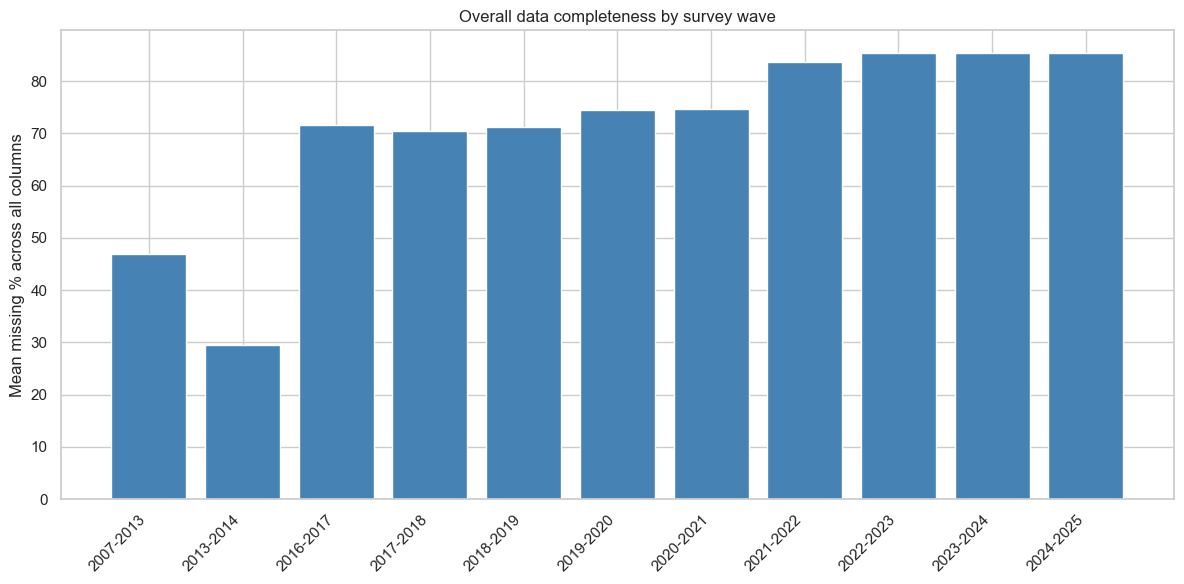

In [58]:
fig, ax = plt.subplots(figsize=(12, 6))
miss_by_dataset = [datasets[l].isna().mean().mean() * 100 for l in labels]
ax.bar(labels, miss_by_dataset, color="steelblue", edgecolor="white")
ax.set_ylabel("Mean missing % across all columns")
ax.set_title("Overall data completeness by survey wave")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Survey year distribution

The 2007–2013 aggregate file contains multiple `survey_year` values; later files typically represent a single administration year.

In [59]:
year_counts = {}
for label, df in datasets.items():
    year_col = resolve_column(df, CORE_CANDIDATES["survey_year"])
    if year_col:
        vc = df[year_col].value_counts(dropna=False).sort_index()
        year_counts[label] = vc
        print(f"\n{label} — column '{year_col}':")
        print(vc.head(20))
    else:
        print(f"\n{label}: no survey year column found (year inferred from filename: {label})")


2007-2013 — column 'survey_year':
survey_year
2007     5689
2009     8597
2010    24396
2011     8870
2012    23835
2013    18099
Name: count, dtype: int64

2013-2014 — column 'survey_year':
survey_year
2014    17584
Name: count, dtype: int64

2016-2017 — column 'survey':
survey
-Car Accident                                                                      1
-Car accident (s)                                                                  1
-Death of a loved one                                                              1
-Emotional abuse                                                                   1
-Fire                                                                              1
-Near death of a parent                                                            1
-People dying while working                                                        1
-Physical abuse                                                                    1
-Several friends murdered              

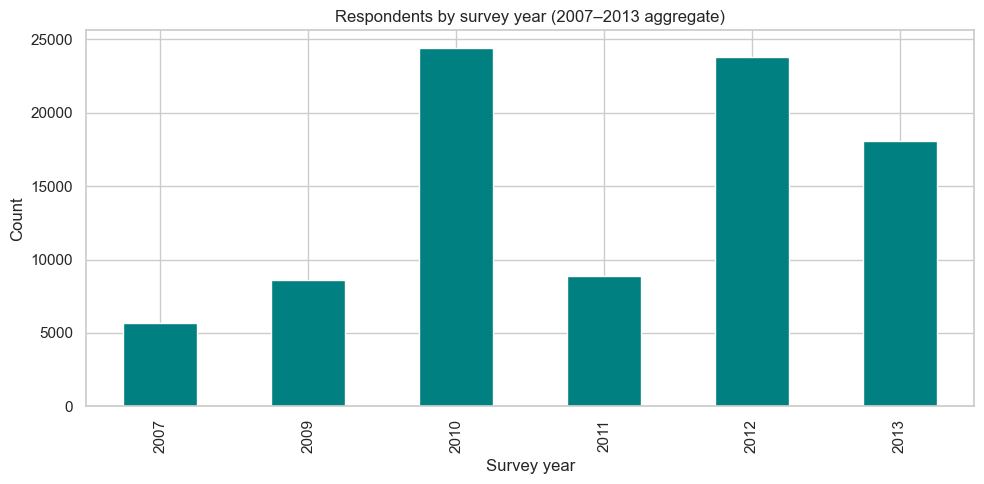

In [60]:
# Plot year distribution for the aggregate file
agg = datasets["2007-2013"]
if "survey_year" in agg.columns:
    agg["survey_year"].value_counts().sort_index().plot(kind="bar", color="teal", edgecolor="white")
    plt.title("Respondents by survey year (2007–2013 aggregate)")
    plt.xlabel("Survey year")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## 8. Demographics

### 8.1 Age

In [61]:
age_stats = []
for label, df in datasets.items():
    if "age" not in df.columns:
        continue
    age = pd.to_numeric(df["age"], errors="coerce")
    age_stats.append({
        "dataset": label,
        "n_valid": age.notna().sum(),
        "mean": age.mean(),
        "median": age.median(),
        "std": age.std(),
        "min": age.min(),
        "max": age.max(),
    })
age_summary = pd.DataFrame(age_stats).round(2)
age_summary

,dataset,n_valid,mean,median,std,min,max
0,2007-2013,89002,4.42,4.0,2.34,1.0,10.0
1,2013-2014,16895,4.42,4.0,2.34,1.0,10.0
2,2016-2017,52645,23.71,21.0,7.03,0.0,118.0
3,2017-2018,66814,22.90,21.0,6.20,0.0,120.0
4,2018-2019,62025,23.06,21.0,6.87,18.0,120.0
5,2019-2020,88702,23.12,21.0,6.60,18.0,120.0
6,2020-2021,137916,23.56,21.0,7.23,18.0,120.0
7,2021-2022,95860,23.40,21.0,7.29,18.0,120.0
8,2022-2023,76406,23.28,21.0,7.19,18.0,120.0
9,2023-2024,104729,23.73,21.0,7.67,18.0,120.0


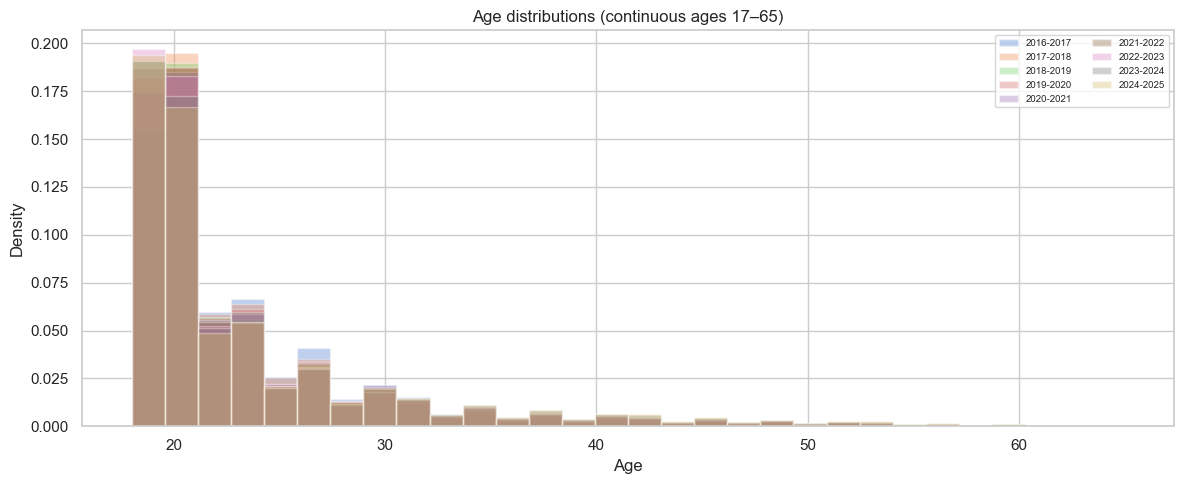

In [62]:
fig, ax = plt.subplots(figsize=(12, 5))
for label, df in datasets.items():
    if "age" not in df.columns:
        continue
    age = pd.to_numeric(df["age"], errors="coerce").dropna()
    # HMS often codes age as categories 1–8 in early years; filter plausible continuous ages
    age_plot = age[(age >= 17) & (age <= 65)]
    if len(age_plot) > 100:
        ax.hist(age_plot, bins=30, alpha=0.35, label=label, density=True)
ax.set_xlabel("Age")
ax.set_ylabel("Density")
ax.set_title("Age distributions (continuous ages 17–65)")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### 8.2 Gender / sex

Coding differs across waves: early files use numeric `gender`; recent files split into `gender_male`, `gender_female`, etc.

In [63]:
def summarize_gender(df: pd.DataFrame) -> pd.Series | None:
    if "gender" in df.columns and df["gender"].dtype != object:
        return df["gender"].value_counts(normalize=True).head(8)
    if "gender_female" in df.columns:
        flags = {
            "female": df["gender_female"].eq(1).sum(),
            "male": df.get("gender_male", pd.Series(0, index=df.index)).eq(1).sum(),
            "nonbinary": df.get("gender_nonbin", pd.Series(0, index=df.index)).eq(1).sum(),
            "trans": df.get("gender_trans", pd.Series(0, index=df.index)).eq(1).sum(),
        }
        total = sum(flags.values()) or 1
        return pd.Series({k: v / total for k, v in flags.items()})
    if "sex_birth" in df.columns:
        return df["sex_birth"].value_counts(normalize=True).head(8)
    return None


for label, df in datasets.items():
    g = summarize_gender(df)
    if g is not None:
        print(f"\n{label}:")
        print((g * 100).round(1).astype(str) + "%")


2007-2013:
gender
1.0    64.5%
2.0    35.3%
3.0     0.2%
Name: proportion, dtype: object

2013-2014:
gender
1.0    61.0%
2.0    38.5%
3.0     0.5%
Name: proportion, dtype: object

2016-2017:
sex_birth
Female      68.3%
Male        31.6%
Intersex     0.1%
3            0.0%
Name: proportion, dtype: object

2017-2018:
gender
2.0    65.7%
1.0    31.7%
5.0     1.5%
6.0     0.6%
3.0     0.4%
4.0     0.1%
Name: proportion, dtype: object

2018-2019:
gender
2.0    66.0%
1.0    31.9%
5.0     1.1%
6.0     0.6%
3.0     0.3%
4.0     0.1%
Name: proportion, dtype: object

2019-2020:
gender
2.0    67.8%
1.0    30.0%
5.0     1.2%
6.0     0.6%
3.0     0.3%
4.0     0.1%
Name: proportion, dtype: object

2020-2021:
female       0.0%
male         0.0%
nonbinary    0.0%
trans        0.0%
dtype: object

2021-2022:
female       68.7%
male         27.7%
nonbinary     3.6%
trans         0.0%
dtype: object

2022-2023:
female       70.3%
male         26.4%
nonbinary     3.4%
trans         0.0%
dtype: object

2023

### 8.3 Race / ethnicity

Early waves use dummy variables (`race_whi`, `race_bla`, …); later waves use multi-select race items.

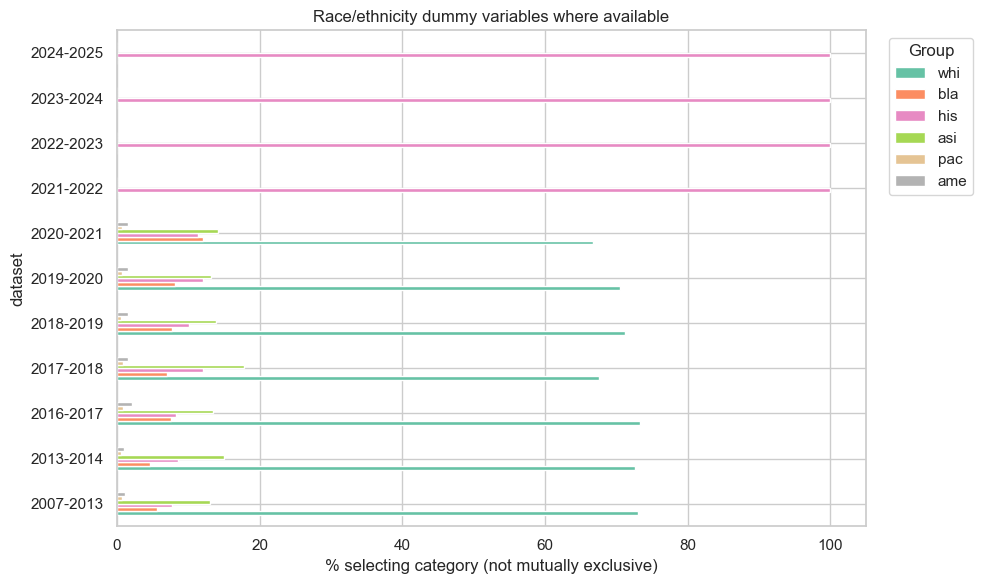

In [64]:
RACE_DUMMIES = ["race_whi", "race_bla", "race_his", "race_asi", "race_pac", "race_ame"]

race_rows = []
for label, df in datasets.items():
    present = [c for c in RACE_DUMMIES if c in df.columns]
    if not present:
        continue
    row = {"dataset": label}
    for c in present:
        row[c.replace("race_", "")] = pd.to_numeric(df[c], errors="coerce").mean()
    race_rows.append(row)

if race_rows:
    race_df = pd.DataFrame(race_rows).set_index("dataset")
    race_pct = (race_df * 100).round(1)
    race_pct.plot(kind="barh", stacked=False, figsize=(10, 6), colormap="Set2")
    plt.xlabel("% selecting category (not mutually exclusive)")
    plt.title("Race/ethnicity dummy variables where available")
    plt.legend(title="Group", bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.show()
    race_pct

## 9. Mental health outcomes

### 9.1 Depression (PHQ-9 / `deprawsc`)

PHQ-9 total score ranges 0–27. Scores ≥10 often indicate moderate-or-worse depression in clinical screening.

In [65]:
def phq_stats(df: pd.DataFrame) -> dict | None:
    if "deprawsc" in df.columns:
        s = pd.to_numeric(df["deprawsc"], errors="coerce")
    elif all(f"phq9_{i}" in df.columns for i in range(1, 10)):
        items = [pd.to_numeric(df[f"phq9_{i}"], errors="coerce") for i in range(1, 10)]
        s = sum(items)
    else:
        return None
    valid = s.dropna()
    if valid.empty:
        return None
    return {
        "n": len(valid),
        "mean": valid.mean(),
        "median": valid.median(),
        "pct_ge10": (valid >= 10).mean() * 100,
        "pct_ge15": (valid >= 15).mean() * 100,
        "pct_ge20": (valid >= 20).mean() * 100,
    }


dep_rows = []
for label, df in datasets.items():
    stats = phq_stats(df)
    if stats:
        stats["dataset"] = label
        dep_rows.append(stats)

dep_summary = pd.DataFrame(dep_rows).set_index("dataset").round(2)
dep_summary

,n,mean,median,pct_ge10,pct_ge15,pct_ge20
dataset,,,,,,
2007-2013,86344,6.28,5.0,21.72,8.08,2.50
2013-2014,16056,6.58,5.0,23.79,9.57,3.38
2016-2017,43120,7.51,6.0,30.01,12.99,4.68
2017-2018,50118,8.05,7.0,33.20,15.57,5.77
2018-2019,44879,8.24,7.0,34.95,16.66,6.62
2019-2020,81461,8.50,7.0,36.68,17.63,6.70
2020-2021,122669,9.22,8.0,41.29,21.55,9.06
2021-2022,85391,9.49,8.0,43.14,22.57,9.39
2022-2023,68633,8.95,8.0,39.84,19.80,7.85


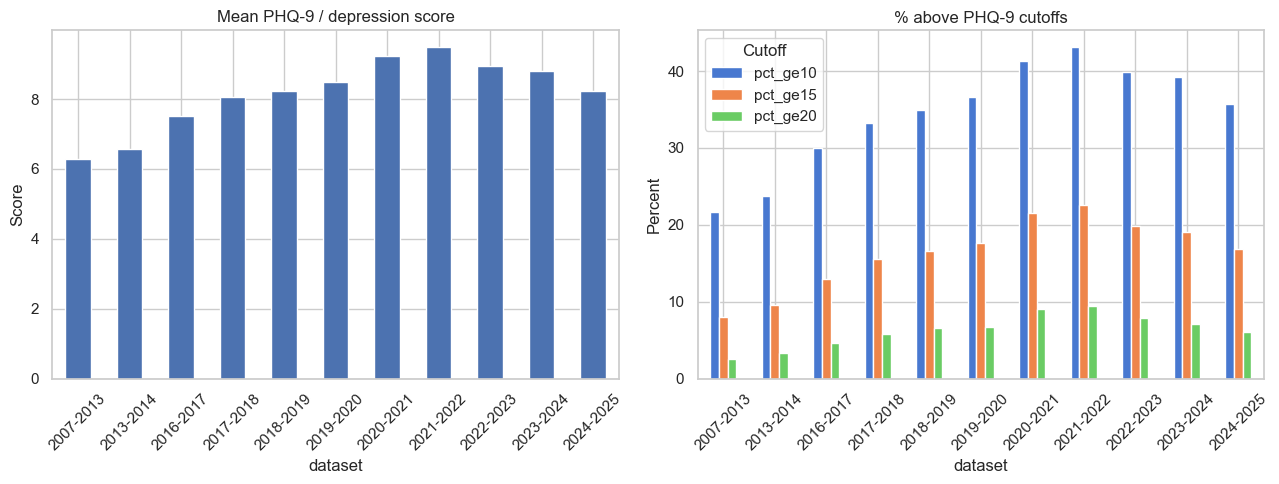

In [66]:
if not dep_summary.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    dep_summary["mean"].plot(kind="bar", ax=axes[0], color="#4C72B0", edgecolor="white")
    axes[0].set_title("Mean PHQ-9 / depression score")
    axes[0].set_ylabel("Score")
    axes[0].tick_params(axis="x", rotation=45)

    dep_summary[["pct_ge10", "pct_ge15", "pct_ge20"]].plot(kind="bar", ax=axes[1], edgecolor="white")
    axes[1].set_title("% above PHQ-9 cutoffs")
    axes[1].set_ylabel("Percent")
    axes[1].tick_params(axis="x", rotation=45)
    axes[1].legend(title="Cutoff")
    plt.tight_layout()
    plt.show()

### 9.2 Anxiety (GAD-7 / `anx_score`)

In [67]:
def gad_stats(df: pd.DataFrame) -> dict | None:
    if "anx_score" in df.columns:
        s = pd.to_numeric(df["anx_score"], errors="coerce")
    elif all(f"gad7_{i}" in df.columns for i in range(1, 8)):
        items = [pd.to_numeric(df[f"gad7_{i}"], errors="coerce") for i in range(1, 8)]
        s = sum(items)
    else:
        return None
    valid = s.dropna()
    if valid.empty:
        return None
    return {
        "n": len(valid),
        "mean": valid.mean(),
        "median": valid.median(),
        "pct_ge10": (valid >= 10).mean() * 100,
    }


anx_rows = []
for label, df in datasets.items():
    stats = gad_stats(df)
    if stats:
        stats["dataset"] = label
        anx_rows.append(stats)

anx_summary = pd.DataFrame(anx_rows).set_index("dataset").round(2)
anx_summary

,n,mean,median,pct_ge10
dataset,,,,
2007-2013,17905,5.34,4.0,17.82
2013-2014,16106,5.54,4.0,19.51
2016-2017,42688,6.54,5.0,26.26
2017-2018,49557,6.89,6.0,28.78
2018-2019,44395,7.18,6.0,30.67
2019-2020,81307,7.38,6.0,31.85
2020-2021,122050,7.98,7.0,35.71
2021-2022,85398,8.29,7.0,38.04
2022-2023,68435,8.10,7.0,36.55


### 9.3 Binary flags: depression, anxiety, comorbidity

In [68]:
flag_rows = []
for label, df in datasets.items():
    row = {"dataset": label}
    for flag in ["dep_any", "dep_maj", "anx_any", "anx_mod", "anx_sev", "dep_or_anx", "dep_or_a"]:
        if flag in df.columns:
            row[flag] = pd.to_numeric(df[flag], errors="coerce").mean() * 100
    flag_rows.append(row)

flags_df = pd.DataFrame(flag_rows).set_index("dataset").round(1)
flags_df

,dep_any,dep_maj,anx_any,anx_mod,anx_sev,dep_or_a,dep_or_anx
dataset,,,,,,,
2007-2013,16.8,9.1,9.7,11.5,6.3,NaN,NaN
2013-2014,18.6,10.4,19.5,12.2,7.3,27.8,NaN
2016-2017,30.1,13.0,26.3,15.7,10.6,38.1,38.1
2017-2018,33.2,15.6,28.8,17.0,11.7,41.2,41.2
2018-2019,34.9,16.7,30.7,17.5,13.2,43.4,43.4
2019-2020,36.7,17.6,31.8,17.7,14.2,45.0,45.0
2020-2021,41.3,21.6,35.7,18.9,16.8,49.4,49.4
2021-2022,43.1,22.6,38.0,20.1,17.9,NaN,51.9
2022-2023,39.8,19.8,36.5,19.7,16.9,NaN,49.5


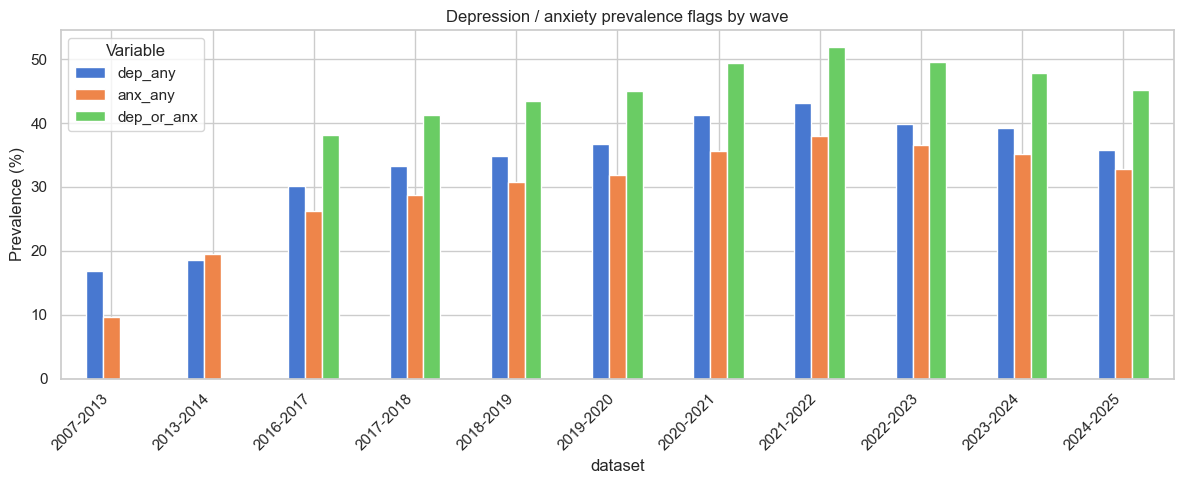

In [69]:
plot_cols = [c for c in ["dep_any", "anx_any", "dep_or_anx"] if c in flags_df.columns]
if plot_cols:
    flags_df[plot_cols].plot(kind="bar", figsize=(12, 5), edgecolor="white")
    plt.ylabel("Prevalence (%)")
    plt.title("Depression / anxiety prevalence flags by wave")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Variable")
    plt.tight_layout()
    plt.show()

### 9.4 Flourishing & positive mental health

In [70]:
flourish_rows = []
for label, df in datasets.items():
    col = resolve_column(df, CORE_CANDIDATES["flourishing"])
    if col:
        s = pd.to_numeric(df[col], errors="coerce")
        flourish_rows.append({
            "dataset": label,
            "variable": col,
            "mean": s.mean(),
            "median": s.median(),
        })
pd.DataFrame(flourish_rows).round(2)

,dataset,variable,mean,median
0,2007-2013,keyes_flourish,0.54,1.0
1,2013-2014,flourish,46.43,48.0
2,2016-2017,flourish,44.23,46.0
3,2017-2018,flourish,44.22,46.0
4,2018-2019,flourish,44.10,46.0
5,2019-2020,flourish,43.55,46.0
6,2020-2021,flourish,43.01,45.0
7,2021-2022,flourish,42.33,44.0
8,2022-2023,flourish,43.13,45.0
9,2023-2024,flourish,43.30,45.0


### 9.5 Suicidal ideation & self-injury

In [71]:
risk_rows = []
for label, df in datasets.items():
    row = {"dataset": label}
    for var in ["sui_idea", "sui_plan", "sui_att", "sib_any"]:
        if var in df.columns:
            row[var] = pd.to_numeric(df[var], errors="coerce").mean() * 100
    risk_rows.append(row)

risk_df = pd.DataFrame(risk_rows).set_index("dataset").round(2)
risk_df

,sui_idea,sui_plan,sui_att,sib_any
dataset,,,,
2007-2013,6.91,1.90,0.53,15.52
2013-2014,9.01,2.71,0.78,18.68
2016-2017,31.17,4.46,1.05,21.25
2017-2018,11.68,4.96,1.22,22.75
2018-2019,12.56,5.70,1.29,22.65
2019-2020,13.11,5.32,1.13,24.00
2020-2021,0.00,4.92,1.12,23.78
2021-2022,14.40,40.75,9.44,28.10
2022-2023,13.30,40.43,11.00,29.22


## 10. Treatment & help-seeking

In [72]:
tx_rows = []
for label, df in datasets.items():
    row = {"dataset": label}
    for var in ["ther_any", "ther_any2", "ther_cur", "ther_lifetime", "meds_any", "meds_cur", "medther", "tx_any", "MH_any"]:
        if var in df.columns:
            row[var] = pd.to_numeric(df[var], errors="coerce").mean() * 100
    tx_rows.append(row)

tx_df = pd.DataFrame(tx_rows).set_index("dataset").round(1)
tx_df

,ther_any,ther_cur,meds_any,ther_any2,meds_cur,medther,ther_lifetime,tx_any,MH_any
dataset,,,,,,,,,
2007-2013,18.2,7.6,15.5,NaN,NaN,NaN,NaN,NaN,NaN
2013-2014,22.0,9.7,16.5,35.2,12.2,28.8,NaN,NaN,NaN
2016-2017,25.5,11.5,23.2,38.7,17.0,35.7,43.3,NaN,NaN
2017-2018,27.2,12.2,22.0,41.0,16.3,36.1,43.8,32.5,54.3
2018-2019,30.0,14.2,23.4,43.5,18.1,39.0,46.0,34.4,NaN
2019-2020,30.5,13.8,23.6,42.2,18.3,39.2,47.5,35.0,NaN
2020-2021,31.7,17.4,25.0,41.4,20.3,41.1,49.6,35.0,NaN
2021-2022,39.0,55.4,29.2,NaN,25.0,NaN,55.4,48.2,NaN
2022-2023,38.4,28.6,29.5,NaN,25.2,NaN,55.3,47.9,NaN


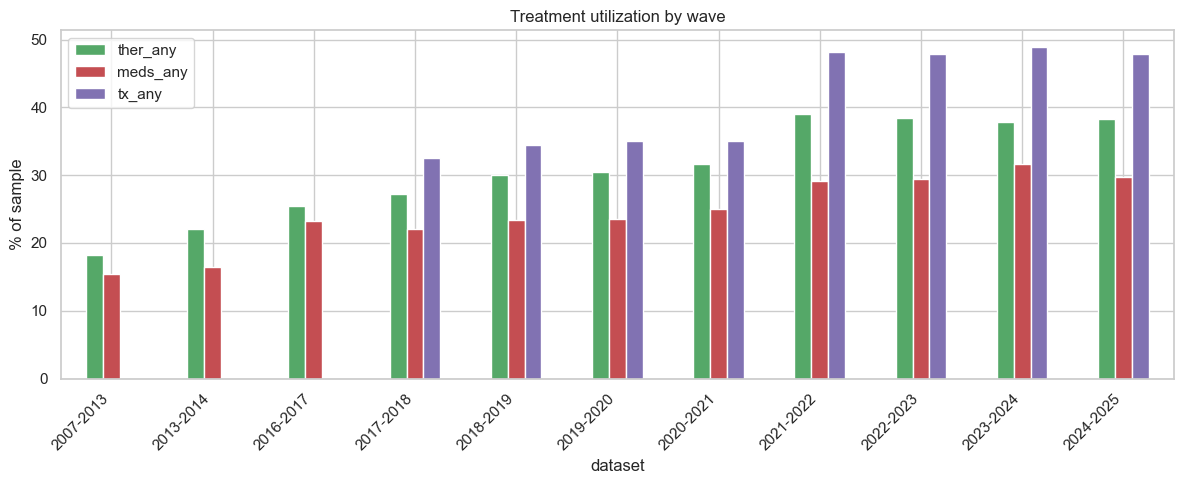

In [73]:
tx_plot_cols = [c for c in ["ther_any", "meds_any", "tx_any"] if c in tx_df.columns]
if tx_plot_cols:
    tx_df[tx_plot_cols].plot(kind="bar", figsize=(12, 5), color=["#55A868", "#C44E52", "#8172B2"], edgecolor="white")
    plt.ylabel("% of sample")
    plt.title("Treatment utilization by wave")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 11. Substance use

In [74]:
SUB_VARS = ["sub_any", "sub_cig", "sub_mar", "sub_coc", "sub_her", "binge_fr", "binge1pl", "binge3pl", "alc_any", "smok_cig"]

sub_rows = []
for label, df in datasets.items():
    row = {"dataset": label}
    for var in SUB_VARS:
        if var in df.columns:
            val = df[var]
            if val.dtype == object:
                row[var] = val.notna().mean() * 100  # presence of response
            else:
                row[var] = pd.to_numeric(val, errors="coerce").mean() * 100
    sub_rows.append(row)

sub_df = pd.DataFrame(sub_rows).set_index("dataset").round(1)
sub_df

,sub_cig,sub_mar,sub_coc,sub_her,binge_fr,binge1pl,binge3pl,sub_any,alc_any,smok_cig
dataset,,,,,,,,,,
2007-2013,174.2,184.3,112.8,101.3,193.5,NaN,NaN,NaN,NaN,NaN
2013-2014,13.1,17.6,1.4,0.1,186.6,42.4,14.1,NaN,NaN,NaN
2016-2017,11.4,21.2,2.0,0.1,NaN,NaN,NaN,22.4,86.6,NaN
2017-2018,10.1,21.5,2.2,0.0,NaN,NaN,NaN,23.0,62.0,NaN
2018-2019,8.6,22.7,1.8,0.0,235.7,39.1,13.4,24.3,61.7,NaN
2019-2020,6.4,19.9,1.1,0.0,227.7,33.3,10.7,21.4,54.7,NaN
2020-2021,5.7,20.0,0.8,0.0,218.8,29.1,9.1,21.2,88.3,NaN
2021-2022,6.5,NaN,NaN,NaN,NaN,NaN,NaN,23.8,52.3,NaN
2022-2023,7.3,NaN,NaN,NaN,232.7,34.0,10.8,24.3,52.3,NaN


## 12. Institution characteristics (`instchars` files)

From 2017–2018 onward, each row includes institutional metadata appended by HMS (school type, size, graduation rate, etc.).

In [75]:
INST_COLS = ["inst_type", "inst_size", "inst_public", "inst_geo", "inst_gradrate", "inst_HMSyear", "inst_acarank", "inst_specart"]

inst_present = {}
for label, df in datasets.items():
    cols = [c for c in INST_COLS if c in df.columns]
    if cols:
        inst_present[label] = cols

print("Institution columns available by wave:")
for k, v in inst_present.items():
    print(f"  {k}: {v}")

Institution columns available by wave:
  2017-2018: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_HMSyear', 'inst_acarank', 'inst_specart']
  2018-2019: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_HMSyear', 'inst_acarank', 'inst_specart']
  2019-2020: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_acarank', 'inst_specart']
  2021-2022: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_HMSyear', 'inst_acarank', 'inst_specart']
  2022-2023: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_specart']
  2023-2024: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_specart']
  2024-2025: ['inst_type', 'inst_size', 'inst_public', 'inst_geo', 'inst_gradrate', 'inst_specart']


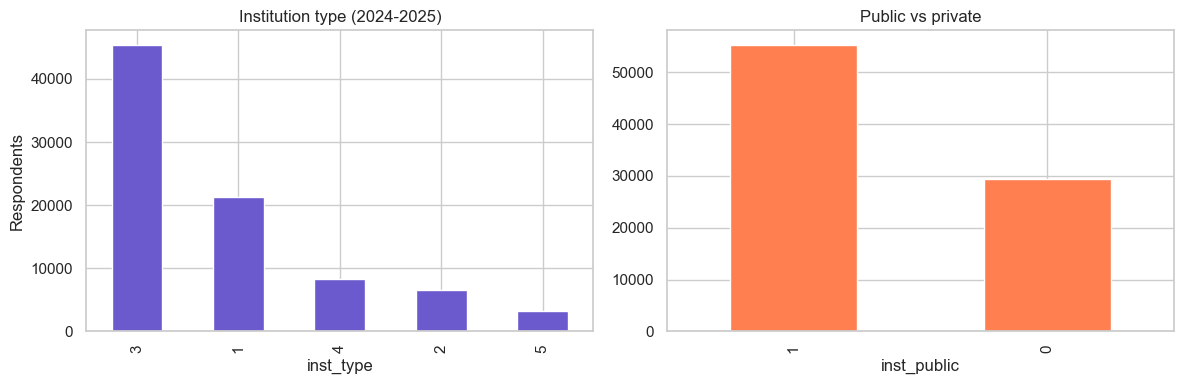

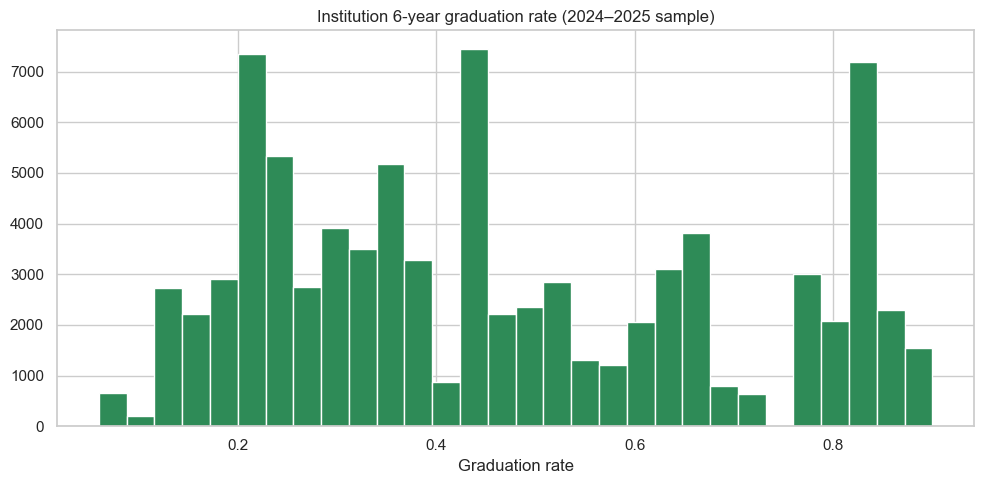

In [76]:
# Example: institution type distribution in the most recent file
latest_label = "2024-2025"
if latest_label in datasets and "inst_type" in datasets[latest_label].columns:
    df_latest = datasets[latest_label]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    df_latest["inst_type"].value_counts().plot(kind="bar", ax=axes[0], color="slateblue", edgecolor="white")
    axes[0].set_title(f"Institution type ({latest_label})")
    axes[0].set_ylabel("Respondents")

    if "inst_public" in df_latest.columns:
        df_latest["inst_public"].value_counts().plot(kind="bar", ax=axes[1], color="coral", edgecolor="white")
        axes[1].set_title("Public vs private")

    plt.tight_layout()
    plt.show()

    if "inst_gradrate" in df_latest.columns:
        gr = pd.to_numeric(df_latest["inst_gradrate"], errors="coerce").dropna()
        gr.hist(bins=30, color="seagreen", edgecolor="white")
        plt.title("Institution 6-year graduation rate (2024–2025 sample)")
        plt.xlabel("Graduation rate")
        plt.tight_layout()
        plt.show()

In [77]:
# Number of unique schools per wave
school_rows = []
for label, df in datasets.items():
    school_col = resolve_column(df, CORE_CANDIDATES["school_id"])
    if school_col:
        school_rows.append({
            "dataset": label,
            "school_col": school_col,
            "n_schools": df[school_col].nunique(),
            "n_respondents": len(df),
            "avg_n_per_school": round(len(df) / df[school_col].nunique(), 1),
        })
pd.DataFrame(school_rows)

,dataset,school_col,n_schools,n_respondents,avg_n_per_school
0,2007-2013,schoolnumber,111,89486,806.2
1,2013-2014,schoolnum,20,17584,879.2
2,2016-2017,schoolnum,54,53888,997.9
3,2018-2019,schoolnum,78,62026,795.2
4,2019-2020,schoolnum,67,88703,1323.9
5,2020-2021,schoolnum,140,137916,985.1
6,2021-2022,schoolnum,133,95860,720.8
7,2022-2023,schoolnum,135,76406,566.0
8,2023-2024,schoolnum,196,104729,534.3
9,2024-2025,schoolnum,135,84735,627.7


## 13. Survey weights (`nrweight`)

HMS provides non-response weights for population inference. Always check the codebook for the correct weight variable in each wave.

In [78]:
weight_rows = []
for label, df in datasets.items():
    if "nrweight" not in df.columns:
        continue
    w = pd.to_numeric(df["nrweight"], errors="coerce").dropna()
    weight_rows.append({
        "dataset": label,
        "n_valid": len(w),
        "mean": w.mean(),
        "median": w.median(),
        "min": w.min(),
        "max": w.max(),
        "sum_weights": w.sum(),
    })
pd.DataFrame(weight_rows).round(3)

,dataset,n_valid,mean,median,min,max,sum_weights
0,2007-2013,89486,1.245,0.935,0.126,46.011,111374.243
1,2013-2014,17584,1.233,0.942,0.250,18.286,21672.731
2,2016-2017,53839,1.029,0.822,0.079,23.351,55404.743
3,2017-2018,66792,0.906,0.651,0.084,52.488,60538.558
4,2018-2019,62005,1.259,0.870,0.086,52.330,78082.316
5,2019-2020,88701,0.838,0.553,0.081,51.692,74360.104
6,2020-2021,137881,1.015,0.628,0.000,69.476,139984.548
7,2021-2022,95860,1.391,0.851,0.000,50.000,133365.941
8,2022-2023,76406,1.768,1.009,0.196,275.000,135090.228
9,2023-2024,104729,1.866,1.149,0.209,93.333,195404.003


## 14. Correlation snapshot (2024–2025)

A quick look at how key numeric mental-health variables relate in the most recent wave.

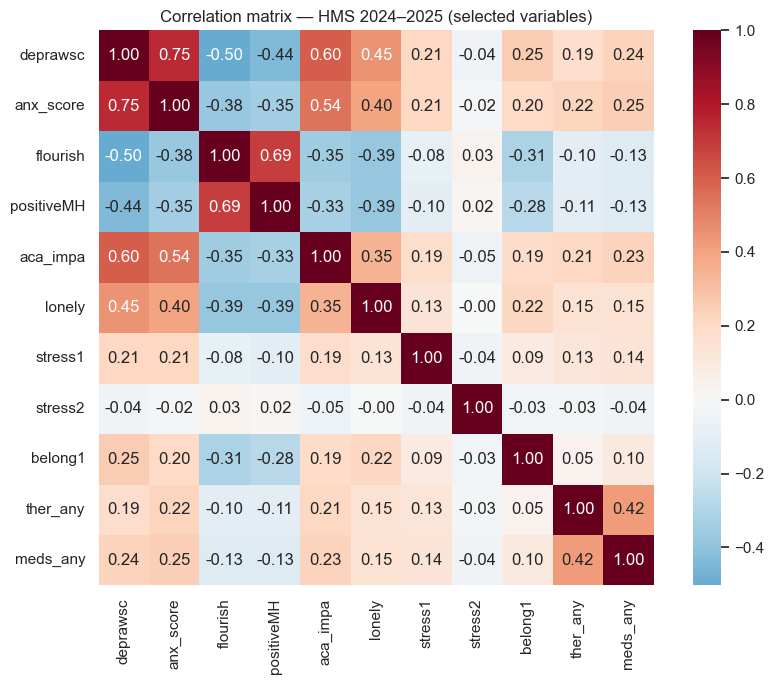

In [79]:
if "2024-2025" in datasets:
    df24 = datasets["2024-2025"]
    corr_cols = [c for c in [
        "deprawsc", "anx_score", "flourish", "positiveMH", "aca_impa",
        "lonely", "stress1", "stress2", "belong1", "ther_any", "meds_any",
    ] if c in df24.columns]

    if len(corr_cols) >= 3:
        corr = df24[corr_cols].apply(pd.to_numeric, errors="coerce").corr()
        plt.figure(figsize=(9, 7))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
        plt.title("Correlation matrix — HMS 2024–2025 (selected variables)")
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough numeric columns for correlation heatmap.")

## 15. Deep dive: single-file explorer

Use this helper to inspect any one dataset interactively.

In [80]:
def explore_dataset(label: str, n_sample: int = 5) -> None:
    """Print a detailed profile of one HMS dataset."""
    if label not in datasets:
        print(f"Unknown label. Choose from: {list(datasets.keys())}")
        return
    df = datasets[label]
    print(f"Dataset: {label}")
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
    print(f"\nColumn names ({len(df.columns)} total):")
    for i, c in enumerate(df.columns):
        print(f"  {i+1:4d}. {c}")
    print(f"\nRandom sample ({n_sample} rows):")
    display(df.sample(min(n_sample, len(df)), random_state=42).T)
    print("\nNumeric describe:")
    display(df.describe(include="number").T.head(20))


# Change the label below to explore a different wave
explore_dataset("2024-2025", n_sample=3)

Dataset: 2024-2025
Shape: 84,735 rows × 1608 columns
Memory: 1203.5 MB

Column names (1608 total):
     1. StartDate
     2. Finished
     3. RecordedDate
     4. responseid
     5. schoolnum
     6. age
     7. gender_male
     8. gender_female
     9. gender_queer
    10. gender_nonbin
    11. gender_trans
    12. gender_prefnoresp
    13. gender_selfID
    14. gender_text
    15. sex_birth
    16. sexual_h
    17. sexual_l
    18. sexual_g
    19. sexual_bi
    20. sexual_queer
    21. sexual_quest
    22. sexual_asexual
    23. sexual_pan
    24. sexual_prefnoresp
    25. sexual_selfID
    26. sexual_text
    27. race_black
    28. race_ainaan
    29. race_asian
    30. race_his
    31. race_pi
    32. race_mides
    33. race_white
    34. race_other
    35. race_other_text
    36. black_african
    37. black_africanam
    38. black_caribbean
    39. black_afrolatin
    40. black_other
    41. asian_east
    42. asian_southeast
    43. asian_south
    44. asian_filipin
    45. asia

,36246,29343,78310
StartDate,12feb2025 19:24:55,02apr2025 21:15:53,13mar2025 19:17:48
Finished,0,1,1
RecordedDate,25feb2025 08:07:11,02apr2025 21:32:12,13mar2025 19:30:35
responseid,R_5auzc8npdULqYA9,R_3pmbuWGrgAbLv2o,R_3nf2FoDO7G4nXXi
schoolnum,55,45,123
...,...,...,...
inst_geo,6,1,8
inst_specart,0,0,0
inst_speccc,0,0,1
inst_gradrate,0.46,0.84,0.14



Numeric describe:


,count,mean,std,min,25%,50%,75%,max
Finished,84735.0,0.783997,0.411519,0.0,1.0,1.0,1.0,1.0
schoolnum,84735.0,68.159544,38.896071,1.0,35.0,64.0,102.0,135.0
age,84735.0,24.063598,8.316806,18.0,19.0,21.0,25.0,99.0
gender_male,23495.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_female,56405.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_queer,2554.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_nonbin,2840.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_trans,2015.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_prefnoresp,536.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_selfID,368.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


## 16. Column search utility

Search for variables by keyword across all files (e.g. `"phq"`, `"stig"`, `"ins_"`).

In [81]:
def search_columns(keyword: str, case_sensitive: bool = False) -> pd.DataFrame:
    rows = []
    for label, df in datasets.items():
        for col in df.columns:
            hay = col if case_sensitive else col.lower()
            needle = keyword if case_sensitive else keyword.lower()
            if needle in hay:
                rows.append({"dataset": label, "column": col})
    result = pd.DataFrame(rows)
    print(f"Found {len(result)} matches for '{keyword}'")
    return result


# Examples — uncomment or change the keyword
search_columns("phq").head(20)

Found 128 matches for 'phq'


,dataset,column
0,2007-2013,phq9_1
1,2007-2013,phq9_2
2,2007-2013,phq9_3
3,2007-2013,phq9_4
4,2007-2013,phq9_5
5,2007-2013,phq9_6
6,2007-2013,phq9_7
7,2007-2013,phq9_8
8,2007-2013,phq9_9
9,2007-2013,phq2_1


In [82]:
search_columns("inst_").drop_duplicates("column").head(25)

Found 80 matches for 'inst_'


,dataset,column
0,2017-2018,inst_HMSyear
1,2017-2018,inst_size
2,2017-2018,inst_type
3,2017-2018,inst_public
4,2017-2018,inst_acarank
5,2017-2018,inst_geo
6,2017-2018,inst_specart
7,2017-2018,inst_gradrate
16,2019-2020,inst_hmsyear
23,2019-2020,inst_spec_other


## 17. Export summary tables

Save consolidated metadata for reference outside the notebook.

In [83]:
OUTPUT_DIR = DATA_DIR / "exploration_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

inventory.to_csv(OUTPUT_DIR / "file_inventory.csv", index=False)
if not dep_summary.empty:
    dep_summary.to_csv(OUTPUT_DIR / "depression_by_wave.csv")
if not anx_summary.empty:
    anx_summary.to_csv(OUTPUT_DIR / "anxiety_by_wave.csv")
flags_df.to_csv(OUTPUT_DIR / "mh_flags_by_wave.csv")
tx_df.to_csv(OUTPUT_DIR / "treatment_by_wave.csv")
resolved_df.to_csv(OUTPUT_DIR / "core_variable_mapping.csv")

print(f"Summary tables written to: {OUTPUT_DIR}")

Summary tables written to: C:\Users\test\Desktop\2007-2025 datasets (.csv, .dta)\exploration_outputs


## 18. Simple ML model on cleaned 2024–2025 data

We train a **binary classifier** to predict `dep_or_anx` (elevated depression and/or anxiety) using demographic, behavioral, and campus-context features — **excluding** direct PHQ-9/GAD-7 scores to avoid target leakage.

**Cleaning steps**
1. Keep completed surveys only (`Finished == 1`)
2. Coerce features to numeric; drop rows with missing target
3. Drop rows missing more than 40% of features
4. Impute remaining missing values (median) inside a sklearn pipeline
5. Use survey weights (`nrweight`) during training

**Models:** Logistic Regression (interpretable baseline) and Random Forest (non-linear benchmark).

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay

TARGET = "dep_or_anx"
FEATURES = [
    "age", "gender_male", "gender_female", "gender_nonbin", "gender_trans",
    "international", "fincur", "finpast", "food_worry",
    "sleep_wknight", "sleep_wkend", "exerc",
    "belong1", "belong2", "lonely", "aca_impa", "flourish", "positiveMH",
    "sub_any", "binge1pl", "smok_cig",
    "discrim_race", "discrim_gender", "discrim_sexual",
    "inst_type", "inst_size", "inst_public",
]

# Use in-memory data if already loaded; otherwise read the 2024-2025 file directly
if "2024-2025" in datasets:
    raw24 = datasets["2024-2025"].copy()
else:
    raw24 = read_hms_csv(DATA_DIR / "HMS_2024-2025_PUBLIC_instchars.csv")

ml_cols = FEATURES + [TARGET, "nrweight", "Finished"]
ml_df = raw24[[c for c in ml_cols if c in raw24.columns]].copy()

for col in ml_cols:
    if col in ml_df.columns:
        ml_df[col] = pd.to_numeric(ml_df[col], errors="coerce")

# --- cleaning ---
ml_df = ml_df[ml_df["Finished"] == 1].copy()
ml_df = ml_df.dropna(subset=[TARGET])
ml_df[TARGET] = ml_df[TARGET].astype(int)

min_features = int(0.6 * len(FEATURES))
ml_df = ml_df[ml_df[FEATURES].notna().sum(axis=1) >= min_features].copy()

print(f"Raw 2024-2025 rows: {len(raw24):,}")
print(f"After cleaning:     {len(ml_df):,}")
print(f"Positive rate ({TARGET}): {ml_df[TARGET].mean():.1%}")
ml_df[FEATURES + [TARGET]].describe().T.head(12)

Raw 2024-2025 rows: 84,735
After cleaning:     63,558
Positive rate (dep_or_anx): 44.9%


,count,mean,std,min,25%,50%,75%,max
age,63558.0,24.224519,8.286720,18.0,19.0,21.0,26.0,87.0
gender_male,17588.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_female,42681.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_nonbin,2361.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_trans,1719.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
international,63512.0,0.087117,0.282009,0.0,0.0,0.0,0.0,1.0
fincur,62492.0,2.756817,1.112838,1.0,2.0,3.0,3.0,5.0
finpast,62447.0,3.107227,1.262607,1.0,2.0,3.0,4.0,5.0
food_worry,62509.0,1.345934,0.594410,1.0,1.0,1.0,2.0,3.0
sleep_wknight,28572.0,6.583683,1.410185,1.0,6.0,7.0,7.0,9.0


In [85]:
X = ml_df[FEATURES]
y = ml_df[TARGET]
weights = ml_df["nrweight"]

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, weights, test_size=0.2, random_state=42, stratify=y
)

log_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

rf_clf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

log_reg.fit(X_train, y_train, clf__sample_weight=w_train)
rf_clf.fit(X_train, y_train, clf__sample_weight=w_train)

results = {}
for name, model in [("Logistic Regression", log_reg), ("Random Forest", rf_clf)]:
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    auc = roc_auc_score(y_test, proba)
    results[name] = {"model": model, "proba": proba, "pred": pred, "auc": auc}
    print(f"\n=== {name} | ROC-AUC = {auc:.3f} ===")
    print(classification_report(y_test, pred, digits=3))


=== Logistic Regression | ROC-AUC = 0.857 ===
              precision    recall  f1-score   support

           0      0.803     0.787     0.795      7003
           1      0.745     0.762     0.754      5709

    accuracy                          0.776     12712
   macro avg      0.774     0.775     0.774     12712
weighted avg      0.777     0.776     0.776     12712


=== Random Forest | ROC-AUC = 0.856 ===
              precision    recall  f1-score   support

           0      0.808     0.774     0.791      7003
           1      0.736     0.774     0.755      5709

    accuracy                          0.774     12712
   macro avg      0.772     0.774     0.773     12712
weighted avg      0.776     0.774     0.774     12712



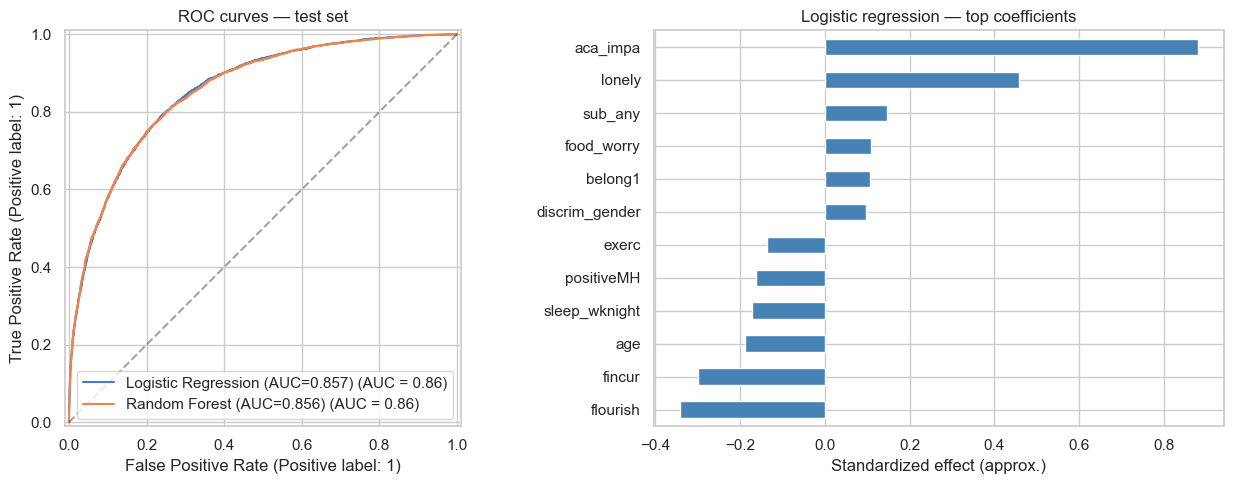


Top Random Forest feature importances:
aca_impa         0.3372
flourish         0.1756
lonely           0.1711
positiveMH       0.0946
fincur           0.0754
food_worry       0.0330
belong1          0.0202
finpast          0.0173
age              0.0146
sleep_wknight    0.0123
dtype: float64


In [86]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, res in results.items():
    RocCurveDisplay.from_predictions(y_test, res["proba"], name=f"{name} (AUC={res['auc']:.3f})", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curves — test set")

# Top coefficients from logistic regression
coefs = pd.Series(
    log_reg.named_steps["clf"].coef_[0],
    index=FEATURES,
).sort_values(key=abs, ascending=False)

coefs.head(12).sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Logistic regression — top coefficients")
axes[1].set_xlabel("Standardized effect (approx.)")

plt.tight_layout()
plt.show()

print("\nTop Random Forest feature importances:")
imp = pd.Series(rf_clf.named_steps["clf"].feature_importances_, index=FEATURES)
print(imp.sort_values(ascending=False).head(10).round(4))

## 19. Key findings & caveats

### Summary
- **11 CSV files** covering roughly **870,000+ respondent records** total (some years pooled).
- Questionnaire length grew from ~500 columns (early years) to **2,300+** in 2019–2020, then stabilized around **1,550–1,680**.
- Core mental-health constructs (PHQ-9, GAD-7, treatment flags) are largely harmonized, but **variable names and coding schemes change** — always consult the official HMS codebook before pooling across years.
- Files from **2017–2018 onward** include **institution characteristics** (`inst_*` columns) enabling school-level analysis.
- Use **`nrweight`** for weighted estimates when the codebook specifies it.

### Important caveats
1. **Not a panel:** Each row is an independent cross-section; the same student is not tracked over time.
2. **School samples differ** each year — trend comparisons reflect both population change and sample composition.
3. **Missing data** is extensive for open-text and skip-logic items; many columns are >90% missing.
4. **Numeric vs. labeled codes:** Some variables store numeric codes, others store string labels (especially 2016–2017+).
5. **Incomplete surveys:** The 2024–2025 file includes rows where `Finished=0` (started but did not complete).

### Recommended next steps
- Download official HMS codebooks from [healthymindsnetwork.org](https://healthymindsnetwork.org/).
- Harmonize variables before pooling (e.g. via `pyreadstat` if you obtain `.dta` files with value labels).
- Apply survey weights for prevalence estimates.
- Filter to completed responses where applicable (`Finished == 1`).